# **TRABAJO PRÁCTICO N° 3 - Minería de Datos**
---
##### 2do. Cuatrimestre - Año 2026

| **Integrantes**           | **Legajo** |
|---------------------------|------------|
| Ruiz, Irma Carolina          | R-4544/6|
| Bartomioli, Ornella  | 47077671   |

##### **Docentes:** Flavio E. Spetale - Ramiro Gatti - Julieta López Ceratto





# Importaciones

In [ ]:
# Análisis exploratorio
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Preparación de los datos
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
# Clasificador SVM
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay ,classification_report)
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.ensemble import RandomForestClassifier


# 1) Limpieza y análisis de los datos.

In [2]:
# Carga y visuaización del conjunto de Datos
cultivos = pd.read_csv('crop_recommendation_geo.csv', sep=";")
cultivos.head()

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,"1,353","6,689","13,5","7,233","11,167","24,867","31,017","16,867","24,868","15,185","31,804","65,161",1148,"126,689","19,228",96,arroz
1,"1,855","11,072","16,9","6,083","15,583","37,217","25,75","15,933","23,829","16,888","29,372","83,058",1740,"81,048","15,206",3,arroz
2,"1,727","14,273",29,"6,4","15,717","26,667",35,"23,683","18,029","7,566","27,969","77,17",1108,"65,502","11,994",316,arroz
3,"1,442","7,527",3,"6,283","18,067","36,7","27,3","19,083","18,042","6,62","28,075","78,908",1483,"51,357","13,621",343,arroz
4,"1,92","12,067","15,8","6,983","16,6","28,733","29,45","18,533","16,284","7,726","24,241","59,99",471,"83,554","16,836",6,arroz


In [3]:
cultivos.info()

<class 'pandas.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   N                       50004 non-null  str  
 1   P                       50004 non-null  str  
 2   exch_bases              50004 non-null  str  
 3   ph                      50003 non-null  str  
 4   soc                     50004 non-null  str  
 5   arcilla                 50004 non-null  str  
 6   arena                   50004 non-null  str  
 7   cec                     50003 non-null  str  
 8   temperatura             50004 non-null  str  
 9   temp_min_mensual        50004 non-null  str  
 10  temp_max_mensual        50004 non-null  str  
 11  humedad                 50003 non-null  str  
 12  lluvia                  50004 non-null  int64
 13  estacionalidad_lluvias  50004 non-null  str  
 14  radiacion_solar         50004 non-null  str  
 15  elevacion               50004 

- El conjunto de datos tiene 50.004 registros y 17 columnas (16 variables predictoras y la variable objetivo clase).
- Solo lluvia y elevacion se cargaron como numéricas (int64). Las otras 15 columnas se leyeron como texto. En clase eso es lo esperable, porque es la variable categórica objetivo. En las 14 restantes, que deberían ser numéricas, se debe a que el archivo usa coma como separador decimal (por ejemplo, 1,353), y por eso pandas no las reconoce como números. En la celda siguiente las convertimos a float reemplazando la coma por punto.
- Las columnas ph, cec y humedad tienen 1 valor faltante cada una. El resto de las columnas están completas.

In [4]:
# Aislamos todas las columnas excepto la variable objetivo 'clase'
variables_numericas = cultivos.drop(columns=['clase']).columns

# Forzamos la conversión a número (float) reemplazando la coma por punto
for col in variables_numericas:
    cultivos[col] = cultivos[col].astype(str).str.replace(',', '.').astype(float)


display(cultivos.describe())

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion
count,50004.000000,50004.000000,50004.000000,50003.000000,50004.000000,50004.000000,50004.000000,50003.000000,50004.000000,50004.000000,50004.000000,50003.000000,50004.000000,50004.000000,50004.000000,50004.000000
mean,1.806235,10.306127,17.864335,6.478587,24.340227,31.240290,36.901901,20.456848,19.240280,11.908296,25.812635,66.837255,1155.215103,72.854064,16.769859,599.722062
std,0.962308,11.114586,11.976382,1.017599,26.461613,8.045335,13.559112,7.744750,7.717546,12.632699,5.250805,12.571507,832.849302,34.707992,2.274059,660.035470
min,0.265000,0.000000,0.100000,4.050000,1.017000,2.400000,0.883000,3.717000,-7.377000,-27.869000,0.585000,28.368000,3.000000,6.203000,6.274000,-161.000000
25%,1.098000,3.680000,7.000000,5.550000,11.017000,25.633000,28.017000,15.550000,14.217000,3.102750,22.238750,56.037000,483.000000,48.141250,15.115000,158.000000
50%,1.632000,6.668000,16.000000,6.500000,18.117000,31.033000,34.683000,19.550000,21.961500,16.445000,26.003500,69.340000,950.000000,68.367500,16.824000,385.000000
75%,2.272000,12.885250,26.500000,7.350000,27.183000,36.767000,45.033000,24.233000,25.789000,22.096750,28.978000,76.962000,1571.000000,94.025000,18.613000,811.000000
max,15.098000,180.000000,143.000000,25.317000,322.817000,142.383000,94.500000,70.817000,44.626000,27.918000,53.006000,148.141000,6759.000000,179.912000,22.882000,5476.000000


### Analisis de las variables

* Nitrógeno (N):

Media: 1.81 | Mediana: 1.63

La Media es ligeramente mayor que la Mediana, lo que sugiere una distribución levemente asimétrica hacia la derecha.

Rango: 0.26 – 15.10

El valor máximo de 15.10 se aleja considerablemente de la media, lo que indica la presencia de muestras de suelo puntuales con concentraciones inusualmente altas de nitrógeno (outliers).

Desviación estándar: 0.96
Presenta una variabilidad moderada, considerando la escala de la variable.

* Fósforo (P):

Media: 10.31 | Mediana: 6.67
La diferencia entre Media y Mediana indica una fuerte distribución asimétrica positiva (sesgada a la derecha).

Rango: 0.00 – 180.00
El valor mínimo en 0 indica muestras sin fósforo disponible, mientras que el máximo extremo de 180 evidencia una amplitud gigantesca y la clara presencia de valores atípicos.

Desviación estándar: 11.11
Muy alta. Al ser mayor que la media, refleja una dispersión enorme en los datos.

* pH del Suelo (ph):

Media: 6.48 | Mediana: 6.50
La Media y la Mediana son prácticamente iguales, mostrando una tendencia central hacia suelos neutros o ligeramente ácidos.

Rango: 4.05 – 25.32
Anomalía detectada: Existe un valor máximo de 25.32, lo cual es químicamente imposible ya que la escala de pH va de 0 a 14. Esto evidencia un error intencional en el registro de los datos.

Desviación estándar: 1.02
A pesar del valor extremo, la baja desviación estándar indica que la inmensa mayoría de las muestras se agrupan sólidamente cerca del 6.5.

* Humedad (humedad):

Media: 66.84 | Mediana: 69.34
La Mediana es algo mayor que la Media, indicando una leve asimetría negativa (sesgo hacia la izquierda).

Rango: 28.37 – 148.14
Anomalía detectada: El rango expone un valor máximo del 148.14%, lo cual excede el 100% límite de la humedad relativa. Nuevamente, se trata de un outlier intencional a tratar.

Desviación estándar: 12.57
Indica una variabilidad considerable en el nivel de humedad entre los distintos climas registrados.

* Lluvia (lluvia):

Media: 1155.22 | Mediana: 950.00
La Media es marcadamente mayor a la Mediana, sugiriendo una distribución asimétrica positiva fuertemente influenciada por zonas de precipitaciones extremas.

Rango: 3.00 – 6759.00
Existe una amplitud abismal entre el valor mínimo (climas áridos) y el máximo (climas extremadamente lluviosos).

Desviación estándar: 832.85
La dispersión es altísima. Esta enorme magnitud justifica la necesidad estricta de aplicar StandardScaler, ya que sin él, esta variable dominaría el entrenamiento del modelo frente a otras de menor escala como el Nitrógeno.

* Arcilla (arcilla):

Media: 31.24 | Mediana: 31.03
Tienen valores casi idénticos, lo que sugiere una distribución bastante simétrica en la mayoría de las muestras.

Rango: 2.40 – 142.38
Anomalía detectada: El valor máximo supera el 100%, lo cual es incoherente para una variable que mide la fracción (porcentaje) de arcilla en el suelo.

Desviación estándar: 8.04
Muestra una variabilidad contenida, a excepción del valor atípico mencionado.

* Carbono Orgánico (soc):

Media: 24.34 | Mediana: 18.12
La fuerte diferencia indica un marcado sesgo positivo por registros elevados aislados.

Rango: 1.01 – 322.82
Un rango extremadamente amplio para este componente del suelo.

Desviación estándar: 26.46
La desviación estándar supera a la propia media, lo que estadísticamente ratifica una dispersión y variabilidad extrema.

* Elevación (elevacion):

Media: 599.72 | Mediana: 385.00
La media está desplazada hacia arriba por terrenos muy elevados.

Rango: -161.00 – 5476.00
La topografía abarca desde depresiones por debajo del nivel del mar (-161 m) hasta tierras altas montañosas (más de 5000 m).

Desviación estándar: 660.04
Alta dispersión, justificando nuevamente el uso de escalado para nivelar su peso algorítmico frente a otras características.

* Radiación Solar (radiacion_solar):

Media: 16.77 | Mediana: 16.82
Ambos valores coinciden casi con exactitud, mostrando una distribución perfectamente simétrica.

Rango: 6.27 – 22.88
Es una de las variables con comportamiento más estable y lógico del conjunto de datos.

Desviación estándar: 2.27
Una desviación muy baja, lo que indica que la mayoría de los cultivos reciben niveles muy uniformes de radiación solar.

### Valores faltantes:

Hay 1 valor faltante en cada una de las columnas ph, cec y humedad, y los tres están en el mismo registro (fila 25085).

In [5]:
display(cultivos[cultivos.isnull().any(axis=1)])

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294.0,63.371,14.632,769.0,cafe


In [28]:
cultivos.isnull().sum()

N                         0
P                         0
exch_bases                0
ph                        1
soc                       0
arcilla                   0
arena                     0
cec                       1
temperatura               0
temp_min_mensual          0
temp_max_mensual          0
humedad                   1
lluvia                    0
estacionalidad_lluvias    0
radiacion_solar           0
elevacion                 0
clase                     0
dtype: int64

In [7]:
display(cultivos[cultivos.duplicated()])

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
104,0.943,2.883,38.6,7.683,11.300,30.700,38.050,14.617,22.899,11.390,32.466,64.663,761.0,115.825,18.054,245.0,arroz
2519,0.788,6.348,20.3,8.450,6.783,33.400,25.450,14.467,23.159,11.400,33.103,60.469,513.0,101.159,17.387,214.0,arroz
6277,2.412,27.711,24.3,6.350,24.567,34.050,9.000,28.267,10.934,-4.322,23.937,74.210,989.0,24.634,13.777,211.0,maiz
8610,2.007,21.651,31.0,8.050,18.833,30.800,29.233,27.033,4.083,-18.845,22.807,59.873,497.0,110.120,13.945,171.0,maiz
9802,0.900,3.000,36.0,8.267,6.567,20.017,40.567,17.550,7.690,-7.076,21.021,55.607,329.0,87.653,15.791,1681.0,maiz
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49895,1.485,15.041,29.0,7.367,13.133,42.750,11.867,24.133,6.377,-11.294,21.838,59.891,296.0,69.575,13.707,778.0,lenteja
49909,2.080,19.243,21.8,7.033,20.700,29.817,38.600,23.200,2.383,-16.585,18.172,75.879,376.0,55.589,13.039,606.0,lenteja
49932,1.902,9.092,20.2,7.283,19.250,26.367,27.683,23.617,5.878,-7.665,18.189,59.499,415.0,58.202,13.556,962.0,lenteja
49979,3.347,16.092,21.8,7.250,18.867,28.183,31.850,26.000,3.070,-15.242,18.080,72.152,360.0,60.306,13.205,652.0,lenteja


In [8]:
print("Cantidad de registros duplicados:", cultivos.duplicated().sum())

Cantidad de registros duplicados: 198


In [9]:
# Limpieza: Eliminamos nulos y duplicados
cultivos_limpio = cultivos.dropna().drop_duplicates(keep='first')

print("\nDimensiones del dataset original:", cultivos.shape)
print("Dimensiones tras la limpieza:", cultivos_limpio.shape)


Dimensiones del dataset original: (50004, 17)
Dimensiones tras la limpieza: (49805, 17)


- Se eliminaron en total 199 registros de los 50.004 originales, y el conjunto limpio quedó con 49.805 registros (se descartó un 0,4 % de los datos):

- Valores faltantes (1 registro): los tres valores faltantes (ph, cec y humedad) están en la misma fila. Decidimos eliminarla en lugar de imputar, porque imputar habría significado inventar 3 de las 16 variables predictoras de esa muestra, mientras que eliminarla implica perder un único registro sobre más de 50.000, una pérdida despreciable.
- Registros duplicados (198 registros): se conservó la primera aparición de cada registro y se eliminaron sus copias. Los duplicados exactos no aportan información nueva y, además, en la validación cruzada una misma muestra podría quedar a la vez en el conjunto de entrenamiento y en el de test, lo que inflaría artificialmente las métricas.

Como la cantidad de registros eliminados es muy chica en relación con el total, esta limpieza no afecta la representatividad del conjunto de datos ni el entrenamiento de los modelos.

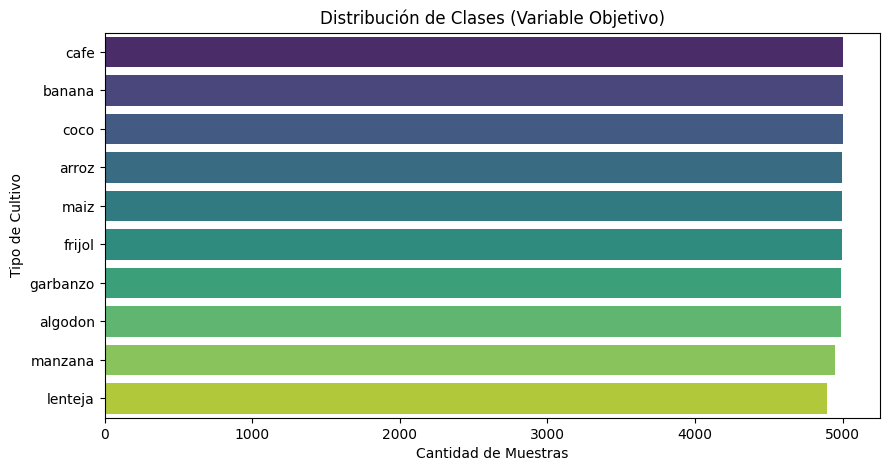

In [10]:
plt.figure(figsize=(10, 5))
# Graficamos la cantidad de muestras por tipo de cultivo
sns.countplot(data=cultivos_limpio, y='clase',
              order=cultivos_limpio['clase'].value_counts().index,
              palette='viridis')
plt.title('Distribución de Clases (Variable Objetivo)')
plt.xlabel('Cantidad de Muestras')
plt.ylabel('Tipo de Cultivo')
plt.show()

Después de la limpieza, las clases quedan entre ~4.890 (lenteja) y ~5.000 muestras (café, banana, coco). Hay un leve desbalance, ya que los duplicados eliminados se concentraban en lenteja y manzana. Por eso usamos métricas con promedio weighted y validación estratificada.

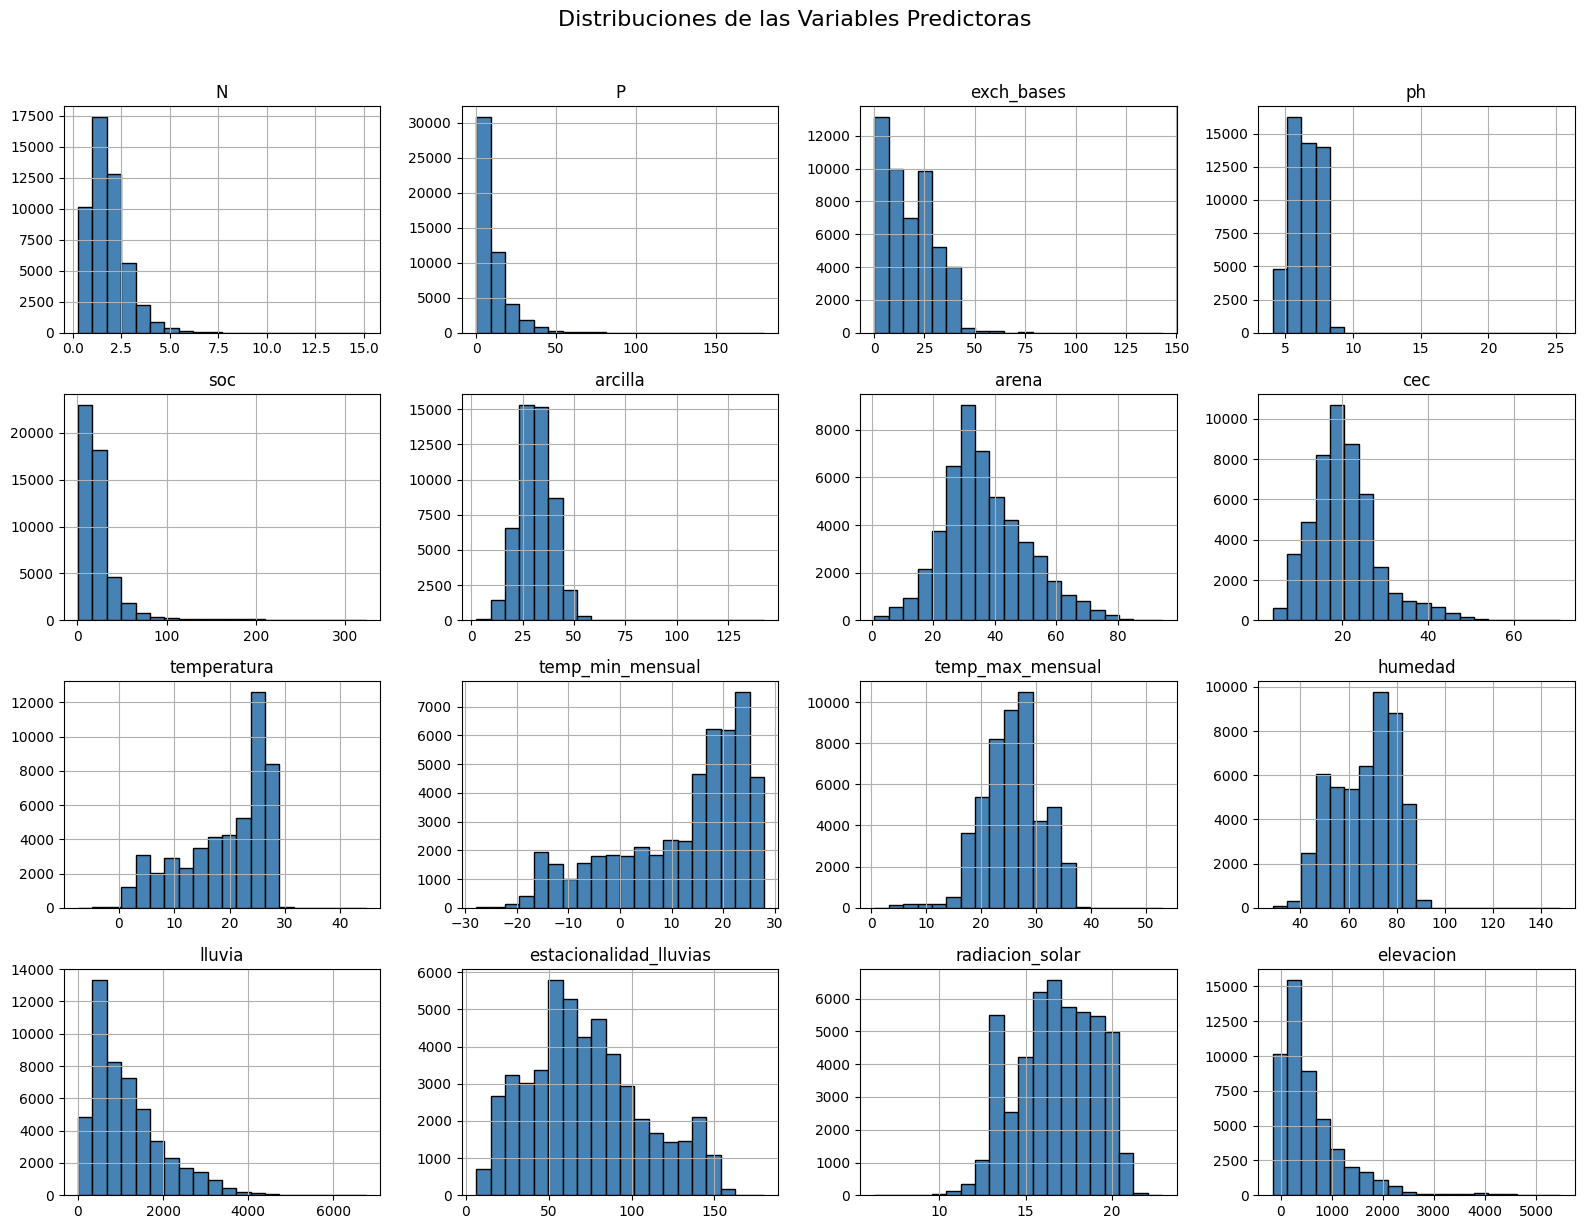

In [11]:
#  Histogramas
cultivos_limpio[variables_numericas].hist(bins=20, figsize=(16, 12), color='steelblue', edgecolor='black')
plt.suptitle('Distribuciones de las Variables Predictoras', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

Las distribuciones se comportan como esperábamos según el análisis de describe():

- Variables químicas del suelo (N, P, soc, exch_bases): fuerte asimetría positiva. La mayoría de las muestras se concentra en valores bajos y hay una cola larga hacia la derecha. En P y soc la cola es muy larga, lo que coincide con que su desvío estándar supera a la media.
- Variables de textura y cec (arcilla, arena, cec): distribuciones más simétricas y acampanadas. En arcilla el eje x llega hasta ~140, aunque casi no se ven barras más allá de 60. Eso confirma que existe un valor aislado por encima del 100 %, imposible para una fracción.
- ph: casi todas las muestras están entre 4 y 9, pero el eje se extiende hasta 25 por el valor imposible ya detectado.
- Variables de temperatura: temperatura y temp_min_mensual tienen asimetría negativa, con una gran concentración en valores cálidos (20–28 °C) y una cola hacia los climas fríos. Es coherente con que la mayoría de los cultivos del conjunto son tropicales o subtropicales (arroz, banana, café, coco, algodón), mientras que la cola fría correspondería a cultivos de clima templado como manzana, lenteja o garbanzo.
- humedad: distribución con más de un pico (alrededor de 50 % y de 75 %), lo que sugiere la presencia de grupos de climas secos y húmedos. Al igual que en ph, el eje se extiende hasta ~148 por el valor imposible.
- lluvia y elevacion: fuerte asimetría positiva. La mayoría de las muestras corresponde a zonas bajas y de lluvias moderadas, con pocos casos de zonas muy lluviosas o de alta montaña.

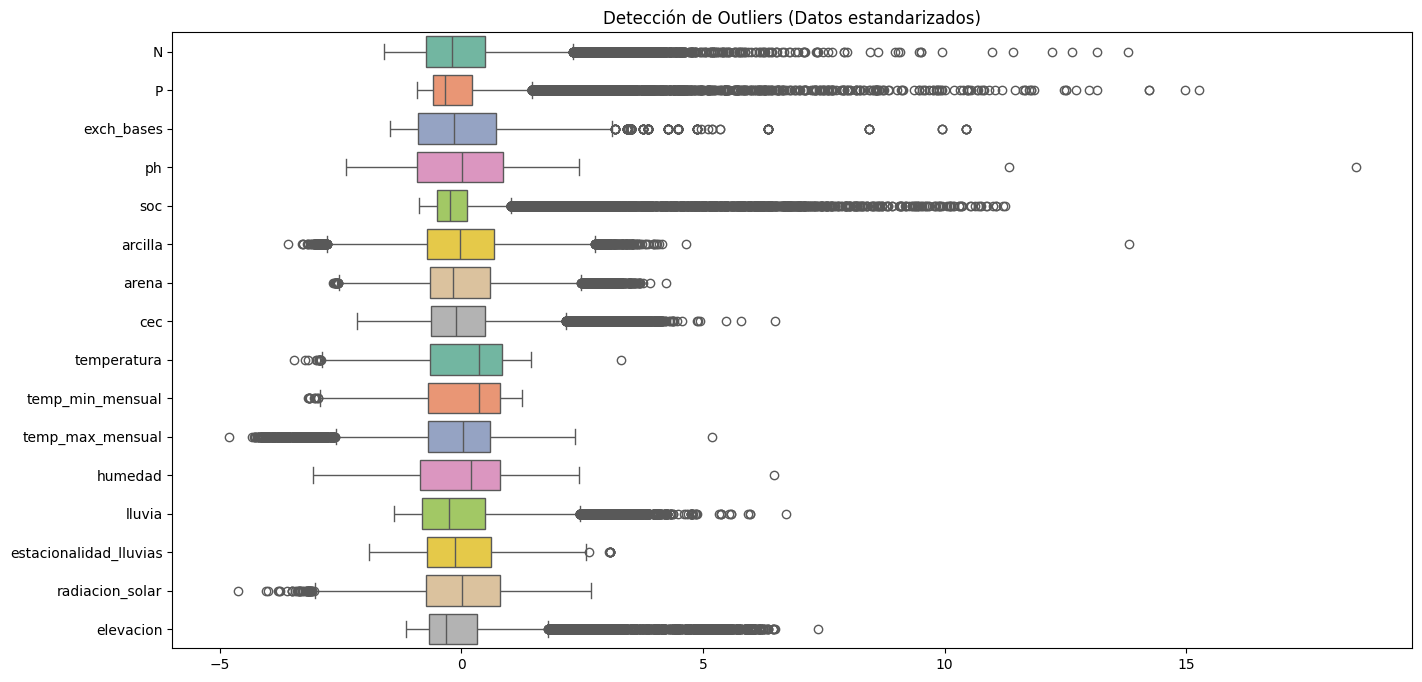

In [12]:
# Boxplots con los datos ya escalados
from sklearn.preprocessing import StandardScaler
scaler_temp = StandardScaler()
datos_grafico_escalados = pd.DataFrame(scaler_temp.fit_transform(cultivos_limpio[variables_numericas]), columns=variables_numericas)

plt.figure(figsize=(16, 8))
sns.boxplot(data=datos_grafico_escalados, orient="h", palette="Set2")
plt.title('Detección de Outliers (Datos estandarizados)')
plt.show()

Al estandarizar, todas las variables quedan en la misma escala y se pueden comparar sus valores atípicos. Distinguimos dos situaciones:

- Muchos outliers formando una cola continua (N, P, soc, cec, lluvia, elevacion, temp_max_mensual por debajo): son consecuencia de las distribuciones asimétricas vistas en los histogramas. Según la regla del rango intercuartílico se marcan como atípicos, pero representan valores posibles en la realidad (suelos muy ricos en materia orgánica, zonas muy lluviosas o de alta montaña) y probablemente sean informativos para distinguir cultivos. Por eso no los tratamos como errores.
- Puntos aislados muy alejados del resto: dos valores de ph (a ~11 y ~18 desvíos de la media), uno de arcilla (~14 desvíos), uno de humedad y uno de temp_max_mensual. Coinciden con los valores físicamente imposibles detectados en el análisis de variables (pH > 14, arcilla > 100 %, humedad > 100 %) y con una temperatura media mensual máxima de 53 °C, muy poco plausible. Interpretamos que son errores introducidos intencionalmente en el conjunto de datos.

Como se trata de muy pocos registros sobre casi 50.000, decidimos mantenerlos: su efecto sobre la media y el desvío usados por el StandardScaler es mínimo, y Random Forest es robusto a valores extremos.

### Análisis de Correlaciones

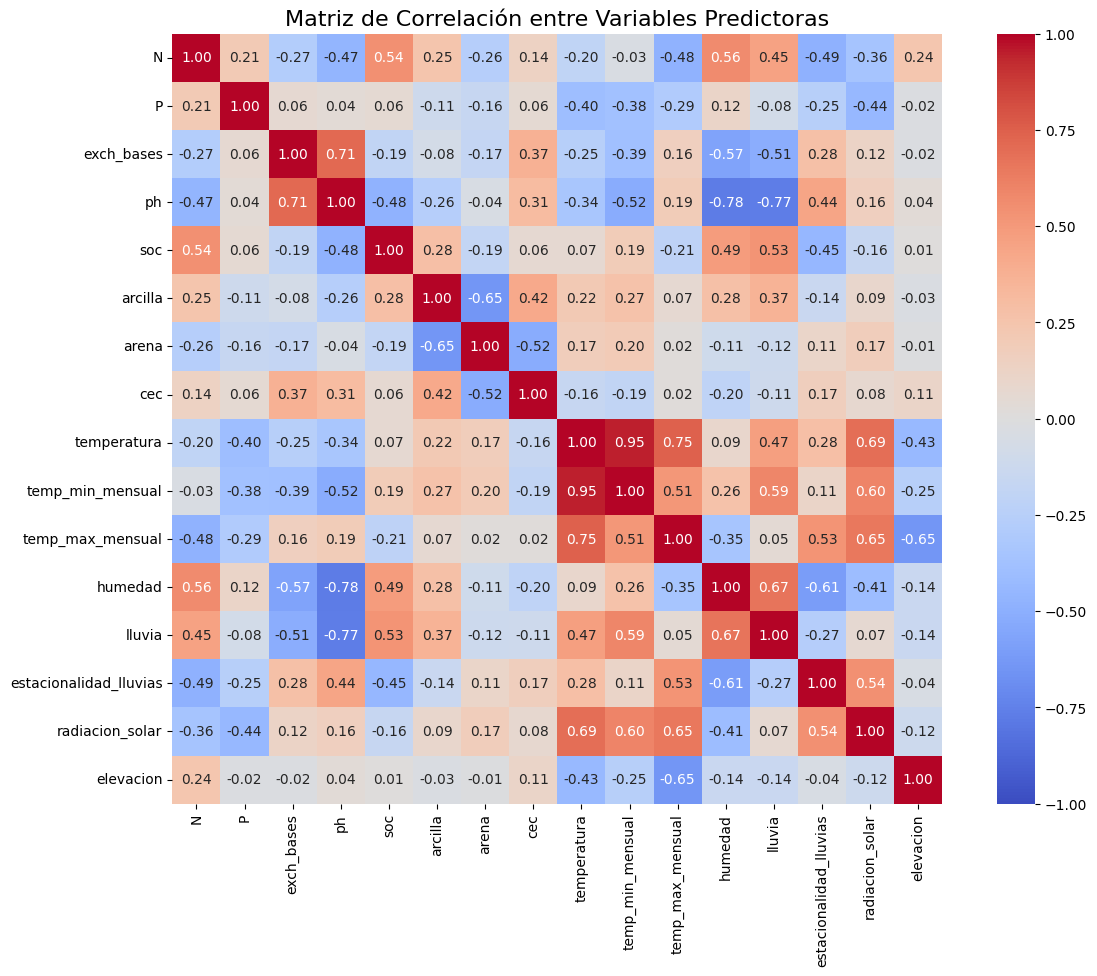

In [13]:
plt.figure(figsize=(14, 10))
# Calculamos la matriz de correlación de Pearson
matriz_correlacion = cultivos_limpio[variables_numericas].corr()

# Graficamos el Heatmap
sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriz de Correlación entre Variables Predictoras', fontsize=16)
plt.show()

Las correlaciones más fuertes son coherentes con relaciones físicas esperables entre las variables:

- temperatura y temp_min_mensual (0,95) y temperatura y temp_max_mensual (0,75): las tres miden aspectos de la temperatura, por lo que hay información redundante entre ellas.
- ph con humedad (−0,78) y con lluvia (−0,77): los suelos de climas húmedos y lluviosos tienden a ser más ácidos, por el lavado de bases. En el mismo sentido, ph y exch_bases (0,71) están correlacionadas positivamente.
- arcilla y arena (−0,65): al ser fracciones de la textura del suelo, cuando aumenta una disminuye la otra.
- humedad y lluvia (0,67): relación climática esperable.

Aunque existe cierta multicolinealidad, decidimos no eliminar variables: SVM incluye regularización y Random Forest no se ve afectado por variables correlacionadas en su capacidad predictiva. Además, una correlación alta entre dos predictoras no indica que alguna de ellas sea irrelevante para separar las clases.

### Preprocesamiento: Codificación y Escalado

In [30]:
# Codificación de la variable objetivo
le = LabelEncoder()

# Definir X e y sobre todo el dataset limpio
X = cultivos_limpio.drop(columns=['clase'])
y = le.fit_transform(cultivos_limpio['clase'])

# Esquema de validación cruzada estratificada con k=5
cv_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=13)

# Métricas requeridas por el enunciado
scoring_metrics = ['accuracy', 'precision_weighted', 'recall_weighted']

- Codificación: la variable objetivo clase se codificó con LabelEncoder, que asigna un entero de 0 a 9 a cada cultivo. Guardamos el codificador (le) para recuperar los nombres de las clases en las matrices de confusión.
- Variables predictoras: X incluye las 16 variables numéricas del conjunto limpio.
- Validación: usamos StratifiedKFold con k=5, shuffle=True y random_state=13, para que cada fold mantenga la proporción de clases del conjunto completo. El mismo esquema se aplica a los tres modelos, lo que permite compararlos en igualdad de condiciones.
- Métricas: accuracy, precision y recall con promedio weighted, por el leve desbalance entre clases.
- Escalado: el StandardScaler no se aplica acá sobre todo el conjunto, sino dentro de un Pipeline junto con el modelo SVM. Así, en cada fold el escalador se ajusta solo con los datos de entrenamiento, lo que evita fuga de información (data leakage) hacia el fold de test. En Random Forest no hace falta escalar, porque los árboles no dependen de la escala de las variables.

# 2) SVM con kernel lineal.

In [ ]:
# Definimos el Pipeline (Escalado + Modelo) para evitar Data Leakage
pipeline_linear = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', random_state=13))
])

In [ ]:
param_grid_linear = {'svm__C': [0.01, 0.1, 1, 10, 100]}

grid_linear = GridSearchCV(
    pipeline_linear,
    param_grid_linear,
    cv=cv_kfold,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    verbose=3
)

grid_linear.fit(X, y)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svm__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision_weighted', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed

In [17]:
# Reporte de resultados
resultados_linear = pd.DataFrame(grid_linear.cv_results_)
cols_reporte = ['param_svm__C', 'mean_test_accuracy', 'std_test_accuracy',
                'mean_test_precision_weighted', 'std_test_precision_weighted',
                'mean_test_recall_weighted', 'std_test_recall_weighted']

print(f"Mejor hiperparámetro SVM Lineal: {grid_linear.best_params_}")
display(resultados_linear[cols_reporte].sort_values(by='mean_test_accuracy', ascending=False))


Mejor hiperparámetro SVM Lineal: {'svm__C': 100}


,param_svm__C,mean_test_accuracy,std_test_accuracy,mean_test_precision_weighted,std_test_precision_weighted,mean_test_recall_weighted,std_test_recall_weighted
4,100.00,0.623512,0.003597,0.623632,0.003887,0.623512,0.003597
3,10.00,0.623090,0.003900,0.623115,0.004179,0.623090,0.003900
2,1.00,0.622046,0.004458,0.621893,0.004958,0.622046,0.004458
1,0.10,0.617569,0.003237,0.616753,0.003867,0.617569,0.003237
0,0.01,0.605160,0.002986,0.604991,0.003666,0.605160,0.002986


- El rendimiento mejora al aumentar C, es decir, al reducir la regularización. El salto más grande ocurre entre C=0,01 y C=1 (de 0,605 a 0,622 de accuracy). A partir de C=1 las métricas se estabilizan: la diferencia entre C=1, C=10 y C=100 es de apenas 0,0015, menor que el desvío estándar entre folds (~0,004). Por lo tanto, esas tres configuraciones son prácticamente equivalentes.
- Los desvíos son bajos en todas las configuraciones (< 0,005), así que el modelo es estable entre folds.
- El recall weighted coincide exactamente con la accuracy. Esto es esperable: al ponderar el recall de cada clase por su cantidad de muestras, el resultado equivale a la proporción total de aciertos.
- Seleccionamos C=100 porque obtiene los mejores valores en las tres métricas. Igual, hay que tener en cuenta que la mejora respecto de C=1 o C=10 es marginal, mientras que el costo computacional es mucho mayor: con C altos el optimizador tarda más en converger, y el tiempo medio de entrenamiento por fold con C=100 fue de unos 2.224 s. Si el tiempo de entrenamiento fuera una restricción, C=1 sería una alternativa razonable con un rendimiento casi idéntico.
- La accuracy máxima de ~62 % es baja para un problema de 10 clases balanceadas. Indica que las clases no son linealmente separables en el espacio de las 16 variables, lo que motiva probar un kernel no lineal (RBF) en la sección siguiente.

In [18]:
# Guardamos el modelo ganador
mejor_svm_linear = grid_linear.best_estimator_

# 3) SVM con kernel gaussiano (RBF).

In [19]:
pipeline_rbf = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', random_state=13))
])

param_grid_rbf = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

In [20]:
grid_rbf = GridSearchCV(pipeline_rbf, param_grid_rbf, cv=cv_kfold,
                        scoring=scoring_metrics, refit='accuracy', n_jobs=-1)
grid_rbf.fit(X, y)

resultados_rbf = pd.DataFrame(grid_rbf.cv_results_)
print(f"Mejor hiperparámetro SVM RBF: {grid_rbf.best_params_}")


Mejor hiperparámetro SVM RBF: {'svm__C': 10, 'svm__gamma': 1}


In [31]:
# Tabla de resultados SVM RBF (media ± desvío en los 5 folds)
cols_reporte_rbf = ['param_svm__C', 'param_svm__gamma',
                    'mean_test_accuracy', 'std_test_accuracy',
                    'mean_test_precision_weighted', 'std_test_precision_weighted',
                    'mean_test_recall_weighted', 'std_test_recall_weighted',
                    'mean_fit_time']

display(resultados_rbf[cols_reporte_rbf]
        .sort_values(by='mean_test_accuracy', ascending=False)
        .round(4))

,param_svm__C,param_svm__gamma,mean_test_accuracy,std_test_accuracy,mean_test_precision_weighted,std_test_precision_weighted,mean_test_recall_weighted,std_test_recall_weighted,mean_fit_time
11,10.0,1.000,0.8852,0.0046,0.8870,0.0043,0.8852,0.0046,179.7564
14,100.0,0.100,0.8837,0.0046,0.8827,0.0046,0.8837,0.0046,74.0395
7,1.0,1.000,0.8809,0.0045,0.8831,0.0044,0.8809,0.0045,174.3680
15,100.0,1.000,0.8789,0.0047,0.8809,0.0044,0.8789,0.0047,151.0640
10,10.0,0.100,0.8680,0.0040,0.8671,0.0041,0.8680,0.0040,52.6302
6,1.0,0.100,0.8243,0.0026,0.8238,0.0027,0.8243,0.0026,56.5090
13,100.0,0.010,0.8060,0.0045,0.8052,0.0046,0.8060,0.0045,86.5770
3,0.1,1.000,0.7606,0.0057,0.8263,0.0049,0.7606,0.0057,207.7625
9,10.0,0.010,0.7509,0.0045,0.7515,0.0046,0.7509,0.0045,72.9289
2,0.1,0.100,0.7408,0.0029,0.7414,0.0030,0.7408,0.0029,90.3799


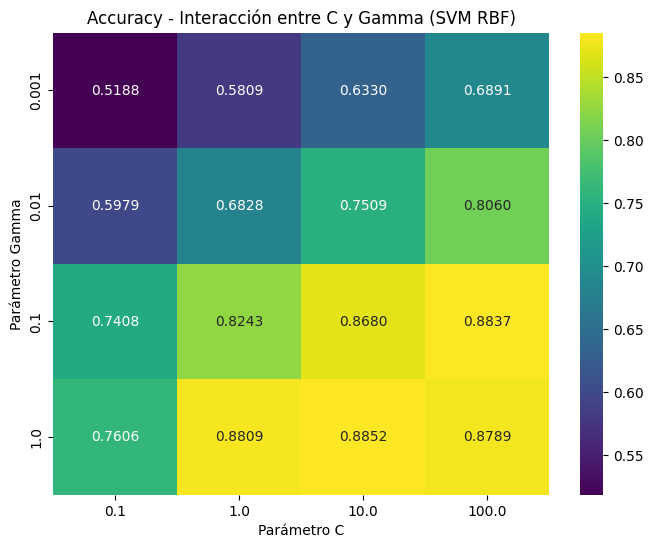

In [ ]:
# Heatmap para visualizar la interacción entre C y Gamma
heatmap_data = resultados_rbf.pivot(index='param_svm__gamma', columns='param_svm__C', values='mean_test_accuracy')
plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".4f", cmap='viridis')
plt.title('Accuracy - Interacción entre C y Gamma (SVM RBF)')
plt.xlabel('Parámetro C')
plt.ylabel('Parámetro Gamma')
plt.show()

El heatmap muestra la accuracy media de validación cruzada para cada combinación de C y gamma:

- Esquina de baja complejidad (C y gamma chicos): con C=0,1 y γ=0,001 la accuracy es de 0,5188, incluso peor que el SVM lineal (~0,62). Con un gamma tan chico, el kernel es muy “ancho” y la frontera de decisión resulta casi lineal. Si además la regularización es fuerte, el modelo subajusta. Aun con C=100, γ=0,001 no supera 0,69.
- Interacción entre C y gamma: la accuracy aumenta al crecer cualquiera de los dos parámetros, y los mejores valores se ubican hacia la esquina inferior derecha. Los parámetros se compensan entre sí: con γ=1 alcanza C=1 para llegar a 0,8809, mientras que con γ=0,1 hace falta C=100 para obtener un resultado similar (0,8837).
- Zona óptima: las combinaciones con γ ∈ {0,1; 1} y C ∈ {1; 10; 100} obtienen entre 0,82 y 0,885. Las cuatro mejores (0,8789 a 0,8852) difieren en menos de 0,007.
- Mejor configuración: C=10, γ=1, con accuracy de 0,8852 ± 0,0046, precision weighted de 0,8870 ± 0,0043 y recall weighted de 0,8852 ± 0,0046. Los desvíos bajos indican que el modelo es estable entre folds.
- Indicio de sobreajuste: con γ=1, pasar de C=10 a C=100 baja la accuracy (de 0,8852 a 0,8789). Al combinar un kernel muy local con poca regularización, la frontera se ajusta demasiado a los datos de entrenamiento y generaliza peor.
- Óptimo en el borde de la grilla: el mejor gamma es el valor más alto explorado (γ=1), por lo que no podemos descartar que un gamma mayor funcione mejor. Sin embargo, la caída observada con C=100 sugiere que el modelo ya está cerca del límite de complejidad, y una mejora adicional probablemente sería marginal.
- Tiempo de entrenamiento: la combinación C=100, γ=0,1 obtiene una accuracy casi idéntica a la mejor (0,8837 contra 0,8852, una diferencia menor que el desvío) y entrena en menos de la mitad del tiempo (~74 s contra ~180 s por fold). Además, las configuraciones de baja complejidad son las más lentas (~247 s con C=0,1 y γ=0,001), porque, al subajustar, el modelo necesita muchos más vectores de soporte.

Respecto del SVM lineal, el kernel RBF mejora la accuracy en más de 26 puntos (de 0,6235 a 0,8852). Esto confirma la hipótesis de la sección anterior: las clases no son linealmente separables, y un kernel no lineal captura mucho mejor la estructura del problema. Además, el mejor modelo RBF entrena mucho más rápido que el lineal con C=100: unos 180 s por fold, contra ~2.224 s.

In [22]:
mejor_svm_rbf = grid_rbf.best_estimator_

# 4) Random Forest.

In [23]:
# Instanciamos el modelo directo
rf = RandomForestClassifier(random_state=13, n_jobs=-1)

param_grid_rf = {
    'n_estimators': [50, 100, 200, 500],
    'max_depth': [5, 10, 20, None]
}

grid_rf = GridSearchCV(rf, param_grid_rf, cv=cv_kfold,
                       scoring=scoring_metrics, refit='accuracy', n_jobs=-1)
grid_rf.fit(X, y)

mejor_rf = grid_rf.best_estimator_
print(f"Mejor hiperparámetro Random Forest: {grid_rf.best_params_}")


Mejor hiperparámetro Random Forest: {'max_depth': None, 'n_estimators': 500}


In [32]:
# Tabla de resultados Random Forest (media ± desvío en los 5 folds)
resultados_rf = pd.DataFrame(grid_rf.cv_results_)
cols_reporte_rf = ['param_n_estimators', 'param_max_depth',
                   'mean_test_accuracy', 'std_test_accuracy',
                   'mean_test_precision_weighted', 'std_test_precision_weighted',
                   'mean_test_recall_weighted', 'std_test_recall_weighted',
                   'mean_fit_time']

display(resultados_rf[cols_reporte_rf]
        .sort_values(by='mean_test_accuracy', ascending=False)
        .round(4))

,param_n_estimators,param_max_depth,mean_test_accuracy,std_test_accuracy,mean_test_precision_weighted,std_test_precision_weighted,mean_test_recall_weighted,std_test_recall_weighted,mean_fit_time
15,500,None,0.9163,0.0029,0.9158,0.0029,0.9163,0.0029,134.9926
14,200,None,0.9157,0.0031,0.9152,0.0031,0.9157,0.0031,78.9572
13,100,None,0.9153,0.0031,0.9148,0.0032,0.9153,0.0031,43.1478
12,50,None,0.9137,0.0032,0.9131,0.0033,0.9137,0.0032,21.6928
11,500,20,0.9135,0.0023,0.9132,0.0024,0.9135,0.0023,193.9525
10,200,20,0.9130,0.0024,0.9126,0.0024,0.9130,0.0024,75.1489
9,100,20,0.9129,0.0023,0.9125,0.0024,0.9129,0.0023,38.9384
8,50,20,0.9111,0.0025,0.9106,0.0026,0.9111,0.0025,20.9566
7,500,10,0.8419,0.0041,0.8444,0.0037,0.8419,0.0041,127.5705
6,200,10,0.8413,0.0035,0.8437,0.0031,0.8413,0.0035,51.0436


- Efecto de max_depth: es el hiperparámetro que más influye. Con profundidad 5 la accuracy ronda 0,64, un valor similar al del SVM lineal, porque árboles tan poco profundos subajustan. Con profundidad 10 sube a ~0,84 y con 20 a ~0,913. Pasar de 20 a sin límite (None) agrega apenas ~0,003, una diferencia del orden del desvío entre folds, así que el modelo ya está cerca de su techo.
- Efecto de n_estimators: con una misma profundidad, aumentar la cantidad de árboles mejora muy poco: con max_depth=None, pasar de 50 a 500 árboles sube la accuracy de 0,9137 a 0,9163. Más árboles estabilizan el promedio del ensamble, pero la ganancia es decreciente.
- Ausencia de sobreajuste: a diferencia de un árbol individual, dejar los árboles sin límite de profundidad no empeora el rendimiento en validación. El promedio de muchos árboles entrenados sobre muestras bootstrap distintas compensa la varianza de cada uno.
- Estabilidad: los desvíos son bajos en todas las combinaciones (entre 0,0023 y 0,0061). El más alto corresponde a la configuración más simple (50 árboles, profundidad 5).
- Mejor configuración: n_estimators=500, max_depth=None, con accuracy de 0,9163 ± 0,0029, precision weighted de 0,9158 ± 0,0029 y recall weighted de 0,9163 ± 0,0029. Igual que en los SVM, la mejora respecto de configuraciones más livianas es marginal: con 100 árboles se obtiene 0,9153 (una diferencia menor que el desvío) en unos 43 s por fold, contra ~135 s con 500. Si el tiempo de entrenamiento fuera una restricción, 100 árboles sería una alternativa razonable.

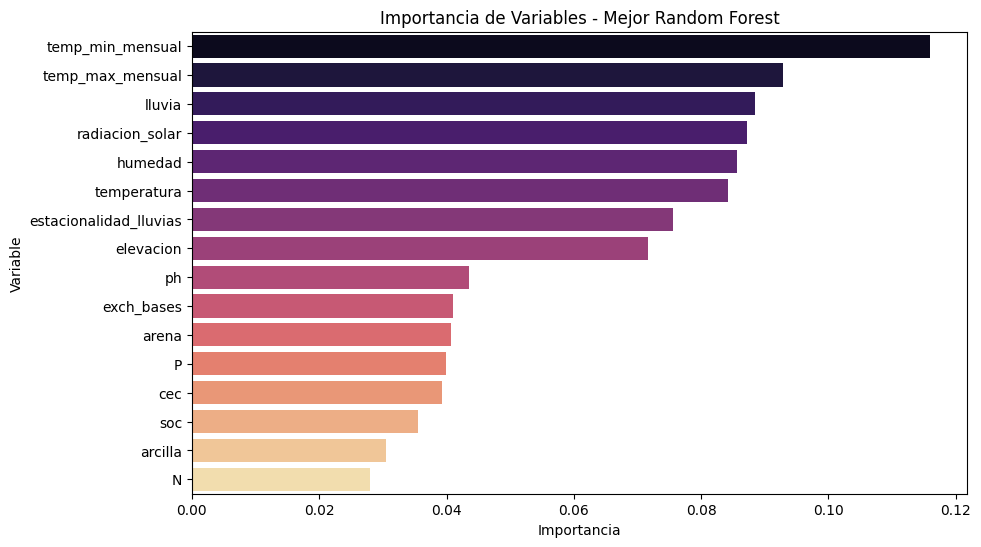

In [ ]:
# Extraer y graficar la importancia de las variables del mejor modelo
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': mejor_rf.feature_importances_
}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importancias, x='Importancia', y='Variable', palette='magma')
plt.title('Importancia de Variables - Mejor Random Forest')
plt.show()

- Las variables climáticas dominan: las ocho más importantes son todas climáticas o geográficas (temp_min_mensual, temp_max_mensual, lluvia, radiacion_solar, humedad, temperatura, estacionalidad_lluvias y elevacion) y suman en conjunto alrededor del 70 % de la importancia total. La más importante es temp_min_mensual (~0,12).
- Las variables de suelo tienen menor peso: cada una aporta entre ~0,03 y ~0,045. La más relevante es ph y la menos relevante es N.
- Coherencia con la hipótesis previa: el resultado coincide con lo observado en los histogramas. Los cultivos se diferencian sobre todo por el clima en el que se dan (tropicales frente a templados), y la temperatura del mes más frío es un buen discriminante entre cultivos que toleran heladas (manzana, lenteja, garbanzo) y cultivos tropicales (coco, banana, café).
- Precaución en la interpretación: esta importancia se calcula a partir de la reducción de impureza. Cuando hay variables muy correlacionadas, como las tres de temperatura (r = 0,95 entre temperatura y temp_min_mensual), la importancia se reparte entre ellas. Por eso cada una puede aparecer con un valor individual menor del que tendría si estuviera sola.

# 5) Comparación de modelos.

In [25]:
# 1. Split adicional 80/20 para evaluación final
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=13
)

In [26]:
# 2. Entrenar los 3 modelos campeones con el 80% final
mejor_svm_linear.fit(X_train_final, y_train_final)
mejor_svm_rbf.fit(X_train_final, y_train_final)
mejor_rf.fit(X_train_final, y_train_final)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

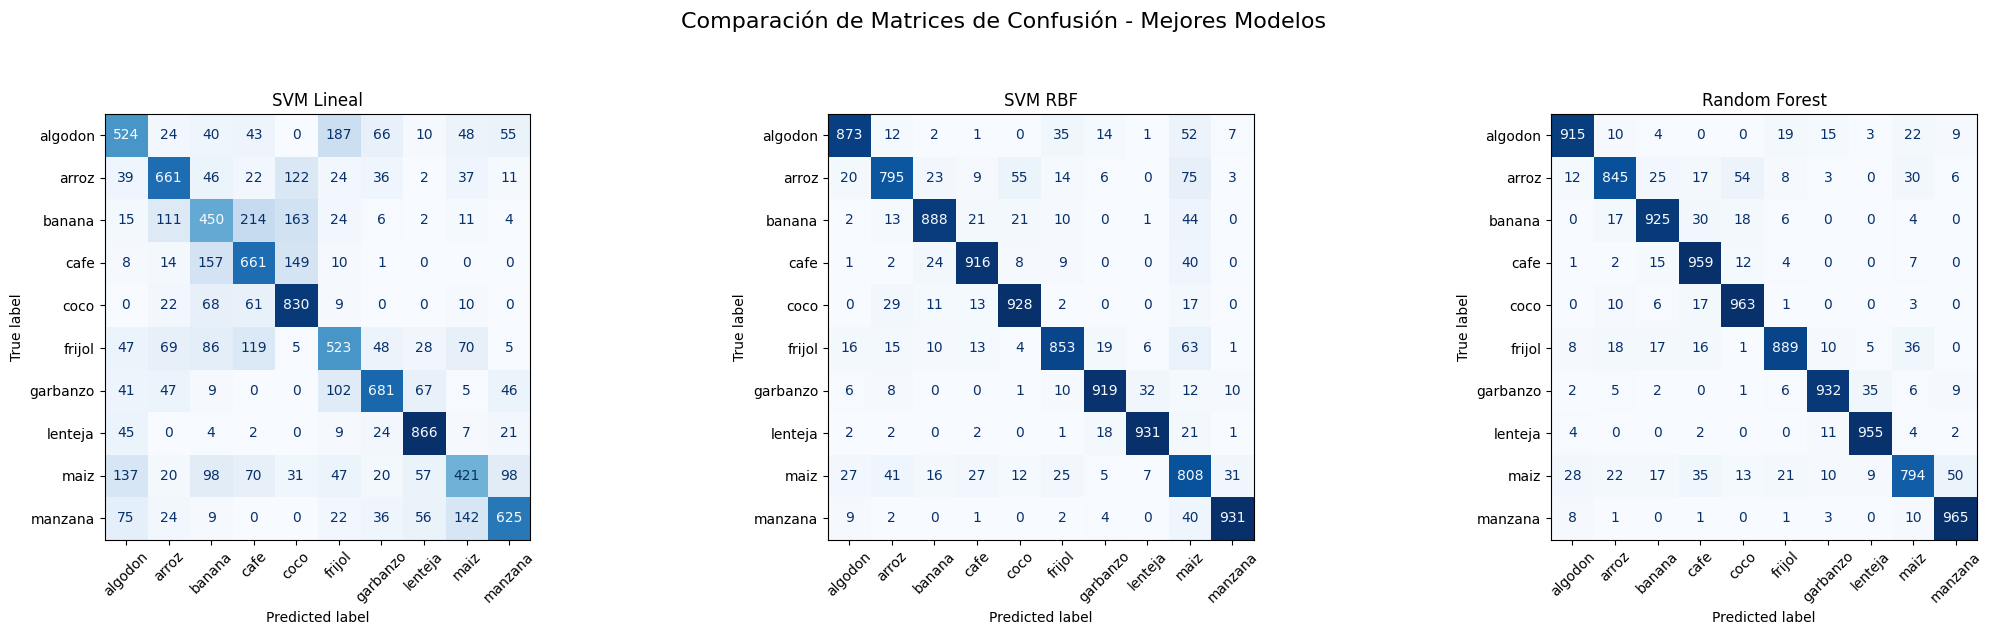

In [ ]:
# Matrices de Confusión en conjunto
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Matriz SVM Lineal
ConfusionMatrixDisplay.from_estimator(
    mejor_svm_linear, X_test_final, y_test_final,
    ax=axes[0], cmap='Blues', colorbar=False, display_labels=le.classes_
)
axes[0].set_title('SVM Lineal')
axes[0].tick_params(axis='x', rotation=45)

# Matriz SVM RBF
ConfusionMatrixDisplay.from_estimator(
    mejor_svm_rbf, X_test_final, y_test_final,
    ax=axes[1], cmap='Blues', colorbar=False, display_labels=le.classes_
)
axes[1].set_title('SVM RBF')
axes[1].tick_params(axis='x', rotation=45)

# Matriz Random Forest
ConfusionMatrixDisplay.from_estimator(
    mejor_rf, X_test_final, y_test_final,
    ax=axes[2], cmap='Blues', colorbar=False, display_labels=le.classes_
)
axes[2].set_title('Random Forest')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Comparación de Matrices de Confusión - Mejores Modelos', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

Las matrices corresponden al split adicional 80/20 (random_state=13, estratificado). La accuracy sobre ese conjunto de test es de 0,627 para el SVM lineal, 0,888 para el SVM RBF y 0,918 para Random Forest. Son valores muy similares a los obtenidos en validación cruzada, lo que confirma que las estimaciones de la sección anterior son confiables.

- SVM lineal: la diagonal es débil y los errores se agrupan entre cultivos de climas parecidos. Banana se confunde con café (214) y con coco (163), café con banana (157) y coco (149), y algodón con frijol (187). Esto es coherente con que estos grupos no se pueden separar con una frontera lineal.
- SVM RBF y Random Forest: ambos tienen una diagonal marcada. Los errores que persisten son pocos y bastante concentrados: arroz se confunde con coco (~55 en ambos), garbanzo con lenteja (dos legumbres de clima templado) y frijol con maíz.
- Maíz es la clase más difícil en los tres modelos: tiene el menor número de aciertos (421, 808 y 794) y además recibe muchas predicciones erróneas de otras clases. Es esperable, porque el maíz se cultiva en un rango climático muy amplio y sus condiciones se superponen con las de muchos otros cultivos. Es la única clase en la que el SVM RBF acierta un poco más que Random Forest.
- Random Forest obtiene la mayor cantidad de aciertos en 9 de las 10 clases, con más de 950 aciertos en café, coco, lenteja y manzana.

In [29]:
def resumen(grid, nombre):
    r = pd.DataFrame(grid.cv_results_).iloc[grid.best_index_]
    return {'Modelo': nombre,
            'Mejores parámetros': grid.best_params_,
            'Accuracy': f"{r.mean_test_accuracy:.4f} ± {r.std_test_accuracy:.4f}",
            'Precision (w)': f"{r.mean_test_precision_weighted:.4f} ± {r.std_test_precision_weighted:.4f}",
            'Recall (w)': f"{r.mean_test_recall_weighted:.4f} ± {r.std_test_recall_weighted:.4f}",
            'Tiempo medio de fit (s)': round(r.mean_fit_time, 1)}

tabla_comparativa = pd.DataFrame([resumen(grid_linear, 'SVM lineal'),
                                  resumen(grid_rbf, 'SVM RBF'),
                                  resumen(grid_rf, 'Random Forest')])
display(tabla_comparativa)

,Modelo,Mejores parámetros,Accuracy,Precision (w),Recall (w),Tiempo medio de fit (s)
0,SVM lineal,{'svm__C': 100},0.6235 ± 0.0036,0.6236 ± 0.0039,0.6235 ± 0.0036,2223.8
1,SVM RBF,"{'svm__C': 10, 'svm__gamma': 1}",0.8852 ± 0.0046,0.8870 ± 0.0043,0.8852 ± 0.0046,179.8
2,Random Forest,"{'max_depth': None, 'n_estimators': 500}",0.9163 ± 0.0029,0.9158 ± 0.0029,0.9163 ± 0.0029,135.0


**Elección del modelo final**

- Métricas: Random Forest obtiene los mejores valores en las tres métricas (accuracy 0,9163, precision 0,9158 y recall 0,9163). Supera al SVM RBF por ~3 puntos y al SVM lineal por ~29.
- Estabilidad: también tiene el menor desvío entre folds (0,0029, contra 0,0046 del RBF y 0,0036 del lineal), así que es el modelo más estable.
- Tiempo de entrenamiento: es el más rápido de los tres (~135 s por fold, contra ~180 s del RBF y ~2.224 s del lineal). Hay que aclarar que Random Forest se entrenó con n_jobs=-1, es decir, en paralelo con varios núcleos, mientras que SVC usa un solo núcleo por entrenamiento, por lo que la comparación no es del todo equitativa. Igual, la diferencia con el SVM lineal es enorme.
- Interpretabilidad: el SVM lineal sería el más interpretable, porque sus coeficientes indican directamente el peso de cada variable, pero su rendimiento (~62 %) lo descarta. Entre los dos modelos competitivos, Random Forest es más interpretable que el SVM RBF: permite analizar la importancia de las variables, mientras que el kernel RBF trabaja en un espacio transformado que no tiene una lectura directa.

Por todo esto, elegimos Random Forest (n_estimators=500, max_depth=None) como el modelo más adecuado para este problema: es el mejor en todos los criterios evaluados.

# Conclusiones
- Calidad de los datos: el conjunto presentaba problemas introducidos intencionalmente: un registro con valores faltantes, 198 duplicados y algunos valores físicamente imposibles (pH > 14, arcilla y humedad > 100 %). Eliminamos los faltantes y los duplicados, con una pérdida del 0,4 % de los datos. Los valores imposibles los detectamos y reportamos, pero los mantuvimos por ser muy pocos y tener un impacto despreciable en los modelos.
- El problema no es linealmente separable: el SVM lineal no supera el 62 % de accuracy, mientras que los modelos no lineales superan el 88 %. Las clases se distribuyen en regiones del espacio de variables que una frontera lineal no puede separar.
- Hiperparámetros: en los tres algoritmos se observó el mismo patrón. El rendimiento mejora rápido al aumentar la complejidad del modelo (C, gamma o max_depth) hasta alcanzar una meseta, a partir de la cual las mejoras son menores que el desvío entre folds, mientras que el costo computacional sigue creciendo. En el SVM RBF, además, con la combinación de máxima complejidad (C=100, γ=1) aparece un indicio de sobreajuste.
- Variables relevantes: el clima es el factor que más distingue a los cultivos (temperatura del mes más frío, temperatura del mes más cálido, lluvia, radiación y humedad), por encima de las propiedades químicas del suelo. Esto coincide con lo observado en el análisis exploratorio.
- Modelo elegido: Random Forest es el más adecuado. Obtiene la mejor accuracy (0,9163 ± 0,0029), es el más estable, el más rápido de entrenar y permite interpretar la importancia de las variables.
- Limitaciones y posibles mejoras:
  - El maíz es la clase peor clasificada en todos los modelos, por la amplitud de condiciones en las que se cultiva.
  - Como trabajo futuro, se podrían corregir los valores imposibles en lugar de mantenerlos.
  - También se podría explorar valores de gamma mayores a 1 en el SVM RBF, ya que el óptimo quedó en el borde de la grilla.
  - Por último, se podría evaluar si eliminar alguna de las variables de temperatura, muy correlacionadas entre sí, simplifica el modelo sin perder rendimiento.